In [3]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("wildfire_data.sqlite")
print(pd.read_sql_query("PRAGMA table_info(FIRES)", conn))

    cid                           name          type  notnull dflt_value  pk
0     0                       OBJECTID       INTEGER        1       None   1
1     1                          Shape  geometryblob        0       None   0
2     2                         FOD_ID         int32        0       None   0
3     3                         FPA_ID     text(100)        0       None   0
4     4             SOURCE_SYSTEM_TYPE     text(255)        0       None   0
5     5                  SOURCE_SYSTEM      text(30)        0       None   0
6     6          NWCG_REPORTING_AGENCY     text(255)        0       None   0
7     7         NWCG_REPORTING_UNIT_ID     text(255)        0       None   0
8     8       NWCG_REPORTING_UNIT_NAME     text(255)        0       None   0
9     9          SOURCE_REPORTING_UNIT      text(30)        0       None   0
10   10     SOURCE_REPORTING_UNIT_NAME     text(255)        0       None   0
11   11           LOCAL_FIRE_REPORT_ID     text(255)        0       None   0

In [4]:
# Load raw data set
relevant_columns = [
    'fire_name',
    'fire_year',
    'discovery_date',
    'discovery_doy',
    'discovery_time',
    'nwcg_cause_classification',
    'nwcg_general_cause',
    'nwcg_cause_age_category',
    'cont_date',
    'cont_doy',
    'cont_time',
    'fire_size',
    'fire_size_class',
    'latitude',
    'longitude',
    'state',
    'fips_name',  # County name
]

query = f"SELECT {', '.join(relevant_columns)} FROM FIRES"

raw_data = pd.read_sql_query(query, conn)
raw_data.columns = raw_data.columns.str.lower()
conn.close()

raw_data.head()

,fire_name,fire_year,discovery_date,discovery_doy,discovery_time,nwcg_cause_classification,nwcg_general_cause,nwcg_cause_age_category,cont_date,cont_doy,cont_time,fire_size,fire_size_class,latitude,longitude,state,fips_name
0,FOUNTAIN,2005,2453403.5,33,1300,Human,Power generation/transmission/distribution,None,2453403.5,33.0,1730,0.10,A,40.036944,-121.005833,CA,Plumas County
1,PIGEON,2004,2453137.5,133,0845,Natural,Natural,None,2453137.5,133.0,1530,0.25,A,38.933056,-120.404444,CA,Placer County
2,SLACK,2004,2453156.5,152,1921,Human,Debris and open burning,None,2453156.5,152.0,2024,0.10,A,38.984167,-120.735556,CA,El Dorado County
3,DEER,2004,2453184.5,180,1600,Natural,Natural,None,2453189.5,185.0,1400,0.10,A,38.559167,-119.913333,CA,Alpine County
4,STEVENOT,2004,2453184.5,180,1600,Natural,Natural,None,2453189.5,185.0,1200,0.10,A,38.559167,-119.933056,CA,Alpine County


In [7]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661383 entries, 0 to 2661382
Data columns (total 17 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   fire_name                  object 
 1   fire_year                  int64  
 2   discovery_date             float64
 3   discovery_doy              int64  
 4   discovery_time             object 
 5   nwcg_cause_classification  object 
 6   nwcg_general_cause         object 
 7   nwcg_cause_age_category    object 
 8   cont_date                  float64
 9   cont_doy                   float64
 10  cont_time                  object 
 11  fire_size                  float64
 12  fire_size_class            object 
 13  latitude                   float64
 14  longitude                  float64
 15  state                      object 
 16  fips_name                  object 
dtypes: float64(6), int64(2), object(9)
memory usage: 345.2+ MB


In [8]:
# Group by class, calculate min/max, sort alphabetically, and loop to print
summary = raw_data.groupby('fire_size_class')['fire_size'].agg(['min', 'max', 'count']).sort_index()

for fire_class, row in summary.iterrows():
    print(f"Fire Class: {fire_class} | Min: {row['min']} | Max: {row['max']} | Count: {int(row['count'])}")


Fire Class: A | Min: 1e-05 | Max: 0.25 | Count: 1031850
Fire Class: B | Min: 0.2501 | Max: 9.99 | Count: 1266682
Fire Class: C | Min: 10.0 | Max: 99.9 | Count: 287261
Fire Class: D | Min: 100.0 | Max: 299.8 | Count: 38957
Fire Class: E | Min: 0.1 | Max: 999.9 | Count: 19867
Fire Class: F | Min: 1000.0 | Max: 4997.0 | Count: 11196
Fire Class: G | Min: 5000.0 | Max: 1054153.0 | Count: 5570


In [9]:
raw_data[(raw_data['fire_size_class'] == 'E') & (raw_data['fire_size'] < 300)]

,fire_name,fire_year,discovery_date,discovery_doy,discovery_time,nwcg_cause_classification,nwcg_general_cause,nwcg_cause_age_category,cont_date,cont_doy,cont_time,fire_size,fire_size_class,latitude,longitude,state,fips_name
2483006,ZION 3,2007,2454297.5,197,1139,Natural,Natural,None,NaN,NaN,None,0.1,E,37.341111,-112.927222,UT,Kane County


In [4]:
raw_data.to_csv("raw_data_export.csv", index=False)

In [10]:
raw_data[raw_data['fire_name'].str.contains('Dakota hill', case=False, na=False)]

,fire_name,fire_year,discovery_date,discovery_doy,discovery_time,nwcg_cause_classification,nwcg_general_cause,nwcg_cause_age_category,cont_date,cont_doy,cont_time,fire_size,fire_size_class,latitude,longitude,state,fips_name
344968,DAKOTA HILL,2007,2454297.5,197,1139,Natural,Natural,None,2454315.5,215.0,2100,9190.00,G,37.340800,-112.926400,UT,Washington County
756396,DAKOTA HILL,1996,2450313.5,231,None,Missing data/not specified/undetermined,Missing data/not specified/undetermined,None,NaN,NaN,None,55.00,C,37.391480,-112.819200,UT,Kane County
1634610,DAKOTA HILL,2013,2456469.5,177,1810,Human,Fireworks,None,2456470.5,178.0,1430,0.10,A,39.872222,-105.541944,CO,Gilpin County
2291515,DAKOTA HILL,2020,2459048.5,200,1715,Human,Recreation and ceremony,None,2459048.5,200.0,2000,0.10,A,39.854306,-105.548210,CO,Gilpin County
2317764,DAKOTA HILL,2021,2459427.5,213,0746,Natural,Natural,None,2459428.5,214.0,1430,0.10,A,37.368556,-112.899412,UT,Kane County
2335646,DAKOTA HILL,2022,2459759.5,180,0443,Natural,Natural,None,2459765.5,186.0,1100,0.25,A,37.344186,-112.929812,UT,Washington County


The Zion 3 Fire appears to be miscategorized as a size E. It was part of the "Dakota Hill Complex" which was much larger, likely the initial smoke jumper event was logged but the rest wasn't properly updated following it's folding into the complex. It'd be simplest to just drop the row.

In [11]:
raw_data = raw_data[raw_data['fire_name'] != 'ZION 3']

In [12]:
raw_data.groupby('nwcg_cause_classification')['fire_size'].mean()

nwcg_cause_classification
Human                                       35.528345
Missing data/not specified/undetermined     62.806884
Natural                                    337.089843
Name: fire_size, dtype: float64

In [13]:
raw_data[raw_data['fire_size_class'] != 'A'].groupby('nwcg_cause_classification')['fire_size'].mean()

nwcg_cause_classification
Human                                       54.887800
Missing data/not specified/undetermined    112.472847
Natural                                    735.895708
Name: fire_size, dtype: float64

In [14]:
raw_data.groupby('nwcg_cause_classification')['fire_size_class'].count()

nwcg_cause_classification
Human                                      2034178
Missing data/not specified/undetermined     270796
Natural                                     356407
Name: fire_size_class, dtype: int64

In [15]:
raw_data['nwcg_general_cause'][raw_data['nwcg_cause_classification'] == 'Human'].unique()

array(['Power generation/transmission/distribution',
       'Debris and open burning',
       'Missing data/not specified/undetermined',
       'Recreation and ceremony', 'Equipment and vehicle use',
       'Arson/incendiarism', 'Fireworks', 'Other causes',
       'Railroad operations and maintenance', 'Smoking',
       'Misuse of fire by a minor', 'Firearms and explosives use'],
      dtype=object)

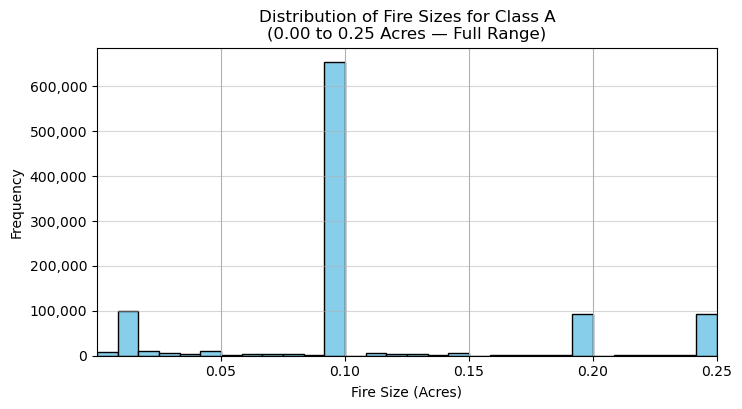

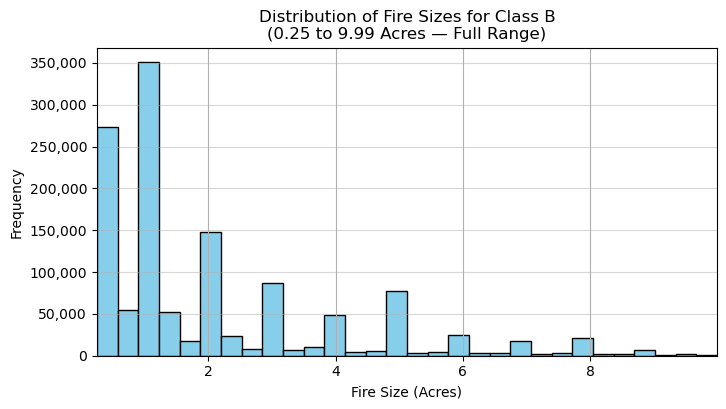

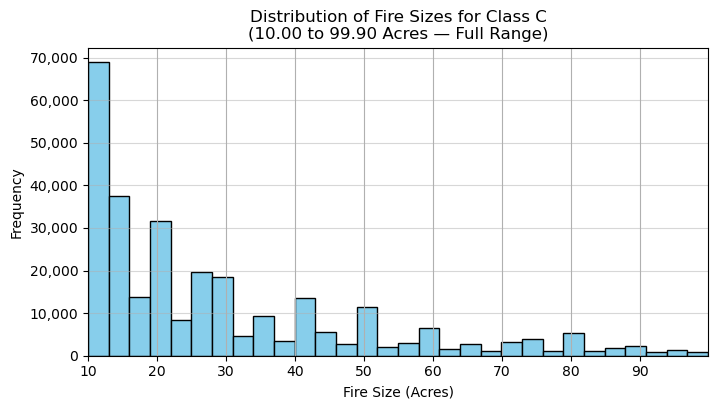

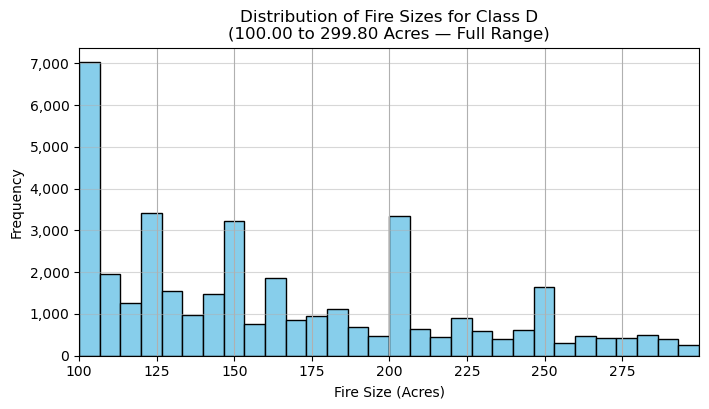

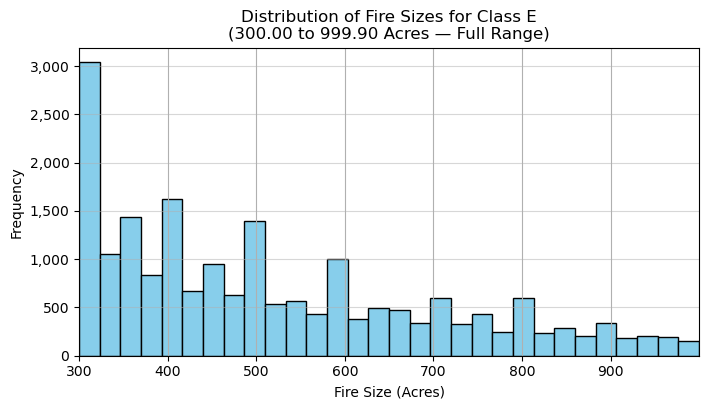

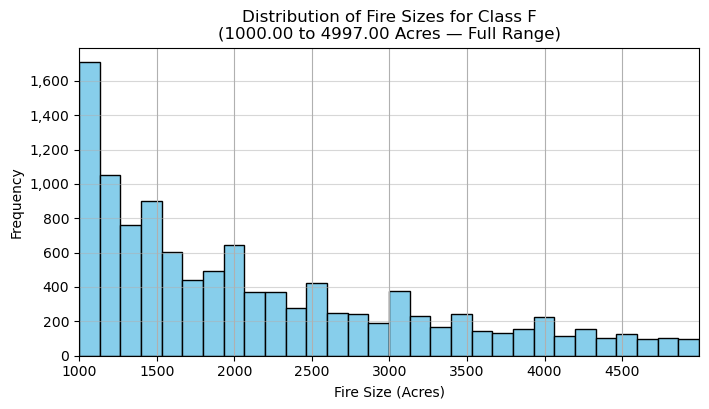

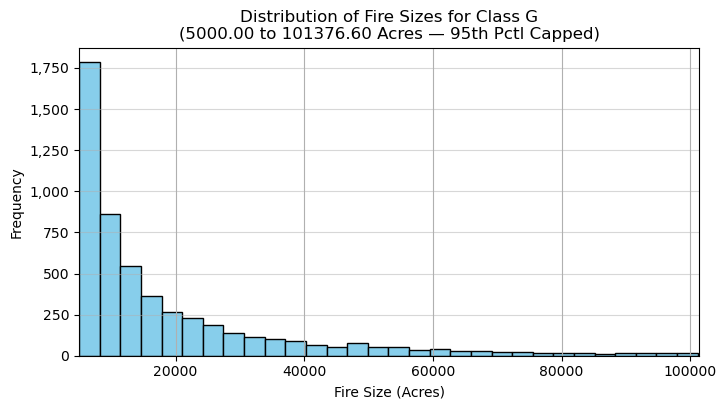

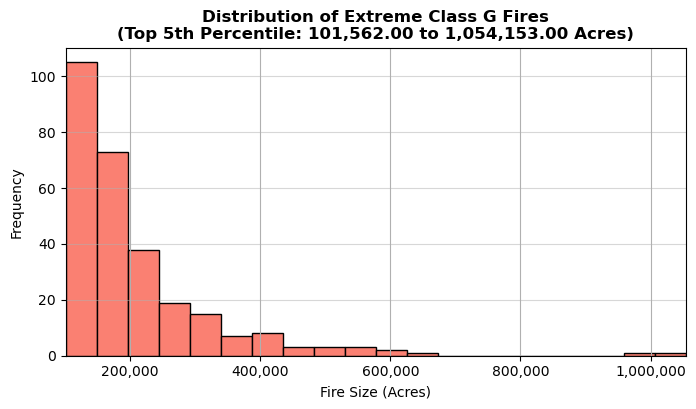

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Get an alphabetically sorted list of unique fire size classes (A to Z)
fire_classes = sorted(raw_data['fire_size_class'].unique())

for fire_class in fire_classes:
    # Filter the dataset for the current class and drop missing values
    class_data = raw_data[raw_data['fire_size_class'] == fire_class]['fire_size'].dropna()
    
    if class_data.empty:
        continue
        
    # Force a fresh, separate figure canvas
    plt.figure(figsize=(8, 4))
    
    # 2. Determine bounds dynamically based on the class
    if fire_class == 'G':
        lower_limit = class_data.min()
        upper_limit = class_data.quantile(0.95)
        title_suffix = f"({lower_limit:.2f} to {upper_limit:.2f} Acres — 95th Pctl Capped)"
    else:
        lower_limit = class_data.min()
        upper_limit = class_data.max()
        title_suffix = f"({lower_limit:.2f} to {upper_limit:.2f} Acres — Full Range)"
        
    # Filter data based on the calculated limits
    filtered_data = class_data[(class_data >= lower_limit) & (class_data <= upper_limit)]
    
    # 3. Plot the histogram
    filtered_data.hist(bins=30, edgecolor='black', color='skyblue')
    plt.xlim(lower_limit, upper_limit)
    
    
    # CLEAN Y-AXIS FORMATTING (No more 1e3 / 1e6 text tricks)
    ax = plt.gca()
    # Turn off automatic scientific notation
    ax.ticklabel_format(style='plain', axis='y')
    # Add commas to large numbers automatically (e.g., 150000 becomes 150,000)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))
    # -------------------------------------------------------------------------
    
    # Format and display
    plt.title(f"Distribution of Fire Sizes for Class {fire_class}\n{title_suffix}")
    plt.xlabel("Fire Size (Acres)")
    plt.ylabel("Frequency")
    plt.grid(axis='y', alpha=0.5)
    plt.show()
    
    # APPENDED EXCEPTION: Extreme Tail Chart right after Class G
    if fire_class == 'G':
        top_5_percent = class_data[class_data >= upper_limit]
        
        if not top_5_percent.empty:
            plt.figure(figsize=(8, 4))
            
            # Plot the extreme tail
            top_5_percent.hist(bins=20, edgecolor='black', color='salmon')
            plt.xlim(top_5_percent.min(), top_5_percent.max())
            
            # CLEAN Y-AXIS FORMATTING FOR TAIL CHART TOO
            ax_tail = plt.gca()
            ax_tail.ticklabel_format(style='plain', axis='y')
            ax_tail.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))
            # Format the X-axis with commas as well for cleaner acre viewing
            ax_tail.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))
            # -----------------------------------------------------------------
            
            # Format and display the appended chart
            plt.title(f"Distribution of Extreme Class G Fires\n(Top 5th Percentile: {top_5_percent.min():,.2f} to {top_5_percent.max():,.2f} Acres)", fontsize=12, fontweight='bold')
            plt.xlabel("Fire Size (Acres)")
            plt.ylabel("Frequency")
            plt.grid(axis='y', alpha=0.5)
            plt.show()


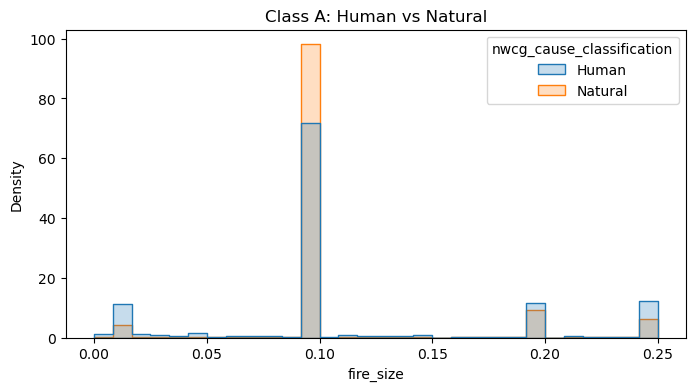

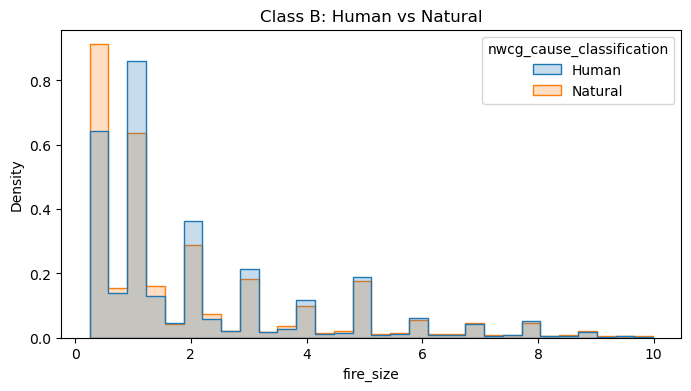

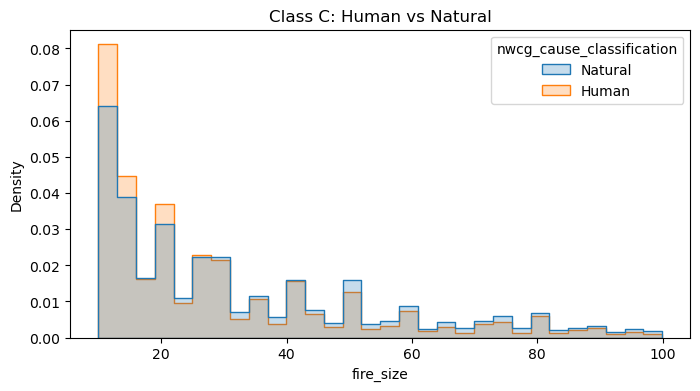

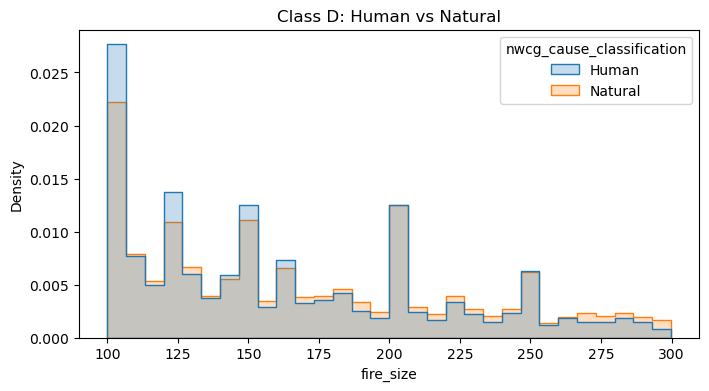

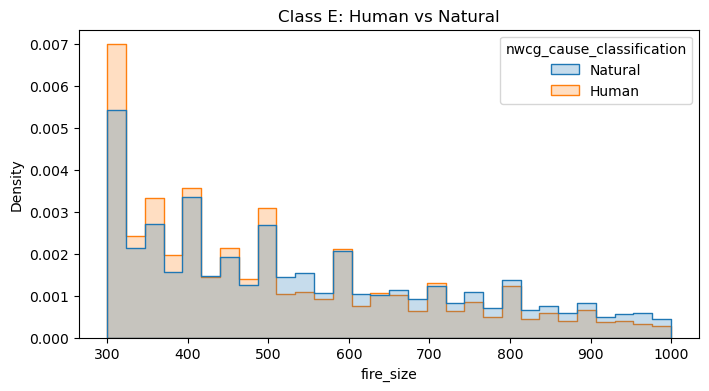

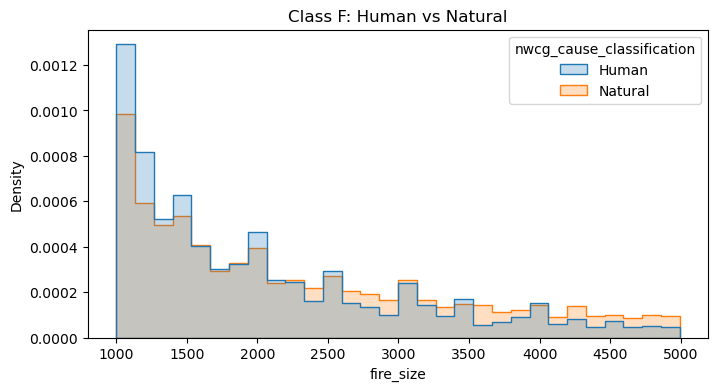

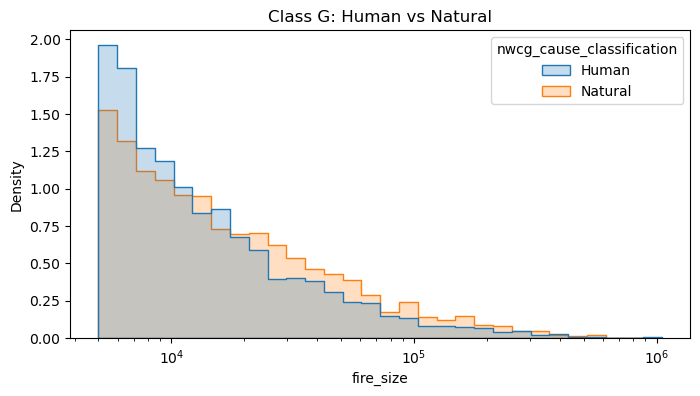

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

d = raw_data[raw_data["nwcg_cause_classification"].isin(["Human", "Natural"])]

for cls, g in d.groupby("fire_size_class"):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(
        data=g, x="fire_size", hue="nwcg_cause_classification",
        stat="density", common_norm=False,
        bins=30, element="step", log_scale=(cls == "G"), ax=ax,
    )
    ax.set_title(f"Class {cls}: Human vs Natural")
    plt.show()

<Axes: xlabel='fire_size', ylabel='Proportion'>

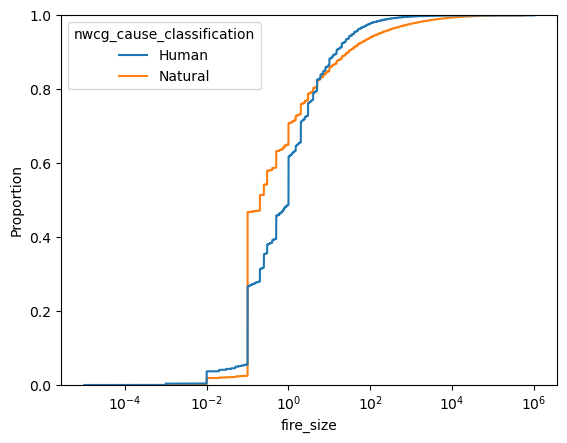

In [25]:
sns.ecdfplot(data=d, x="fire_size",
             hue="nwcg_cause_classification", log_scale=True)

In [26]:
a = d[d["fire_size_class"] == "A"]
print(a.groupby("nwcg_cause_classification")["fire_size"]
        .value_counts(normalize=True)
        .groupby(level=0).head(5))

nwcg_cause_classification  fire_size
Human                      0.10         0.598782
                           0.25         0.101821
                           0.20         0.095383
                           0.01         0.092849
                           0.05         0.011640
Natural                    0.10         0.817510
                           0.20         0.077234
                           0.25         0.050632
                           0.01         0.033756
                           0.05         0.002764
Name: proportion, dtype: float64


In [28]:
from scipy.stats import mannwhitneyu

human = d.loc[d["nwcg_cause_classification"] == "Human", "fire_size"]
natural = d.loc[d["nwcg_cause_classification"] == "Natural", "fire_size"]

u, p = mannwhitneyu(human, natural, alternative="two-sided")
prob_superiority = u / (len(human) * len(natural))
rank_biserial = 2 * prob_superiority - 1